EJERCICIO 1: IMPLEMENTACIÓN TRANSFORMADA DISCRETA DE FOURIER

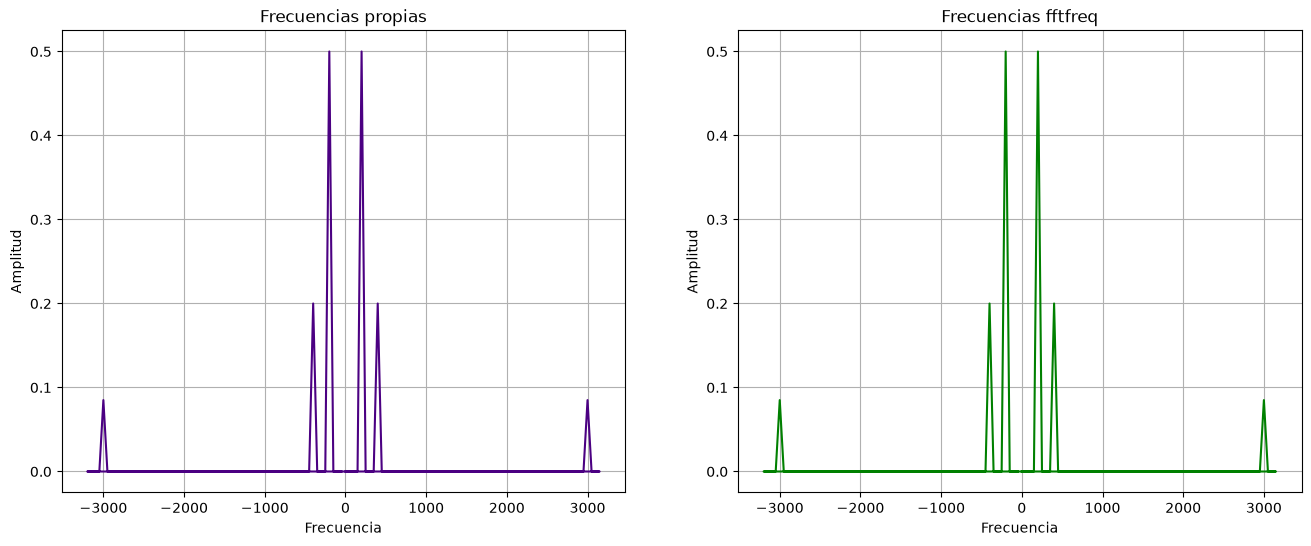

In [176]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq

# Construcción de la señal
N = 128 # number of point in the whole interval
f = 200.0 #  frequency in Hz
dt = 1 / (f * 32 ) #32 samples per unit frequency
t = np.linspace( 0, (N-1)*dt, N)
y = np.cos(2 * np.pi * f * t) - 0.4 * np.sin(2 * np.pi * (2*f) * t )+ 0.17*np.sin(2 * np.pi * (15*f) * t )

# 1) implemente de la transformada de fourier discreta
def Fourier_propia(fun,len):
  """
  inputs:
    fun: La función a la que se le va a aplicar la transformada de fourier
    len: Número de puntos en el intervalo

  output:
    Fr: La transformada de la función inicial
  """
  Fr = np.zeros(len, dtype="complex") #x_k
  n = np.arange(len)

  for k in range(len):
    Fr[k] = np.sum(fun * np.exp(- (0+1j) * 2 * np.pi * k * n / len) )

  return Fr

# 2) Genere el arreglo de las frecuencias (ver documentación de fftfreq):
def Frecuencias_propia(dt, len):
  """
  inputs:
    dt: Las muestras de tiempo base
    len: Número de puntos en el intervalo

  output:
    frecuencias: Un arreglo con las frecuencias de acuerdo al intervalo espacial y el intervalo temporal
  """
  if len % 2 == 0: # Si N es par
    frecuencias = np.zeros(len)
    frecuencias_p1 = np.arange(len/2)          #parte 1, son positivos desde el cero hasta n/2 -1
    frecuencias_p2 = -np.arange(len/2)[::-1]-1 #parte 2, son negativos desde -n/2 hasta -1
    frecuencias[:int(len/2)] = frecuencias_p1 / (dt * len)
    frecuencias[int(len/2):] = frecuencias_p2 / (dt * len)

  if len % 2 == 1: # Si N es impar
    frecuencias = np.zeros(len-1)
    frecuencias_p1 = np.arange((len-1)/2)          #parte 1, son positivos desde el cero hasta (n-1)/2
    frecuencias_p2 = -np.arange((len-1)/2)[::-1]-1 #parte 2, son negativos desde -(n-1)/2 hasta -1
    frecuencias[:int((len-1)/2)] = frecuencias_p1 / (dt * len)
    frecuencias[int((len-1)/2):] = frecuencias_p2 / (dt * len)

  return frecuencias

# 3) Haga una gráfica comparando método propio con implementación de scipy.fftpack.fft
fft_x = fft(y) / N # FFT Normalized
freq = fftfreq(N, dt) # Recuperamos las frecuencias

fig1, (ax1,ax2) = plt.subplots(1,2, figsize=(16,6))

ax1.plot(Frecuencias_propia(dt, N), np.abs(Fourier_propia(y, N))/N, color="indigo")
ax1.grid(True)
ax1.set_ylabel("Amplitud")
ax1.set_xlabel("Frecuencia")
ax1.set_title("Frecuencias propias")

ax2.plot(freq, np.abs(fft_x), color="green")
ax2.grid(True)
ax2.set_ylabel("Amplitud")
ax2.set_xlabel("Frecuencia")
ax2.set_title("Frecuencias fftfreq")

plt.show()

EJERCICIO 2: FILTRO DE FOURIER

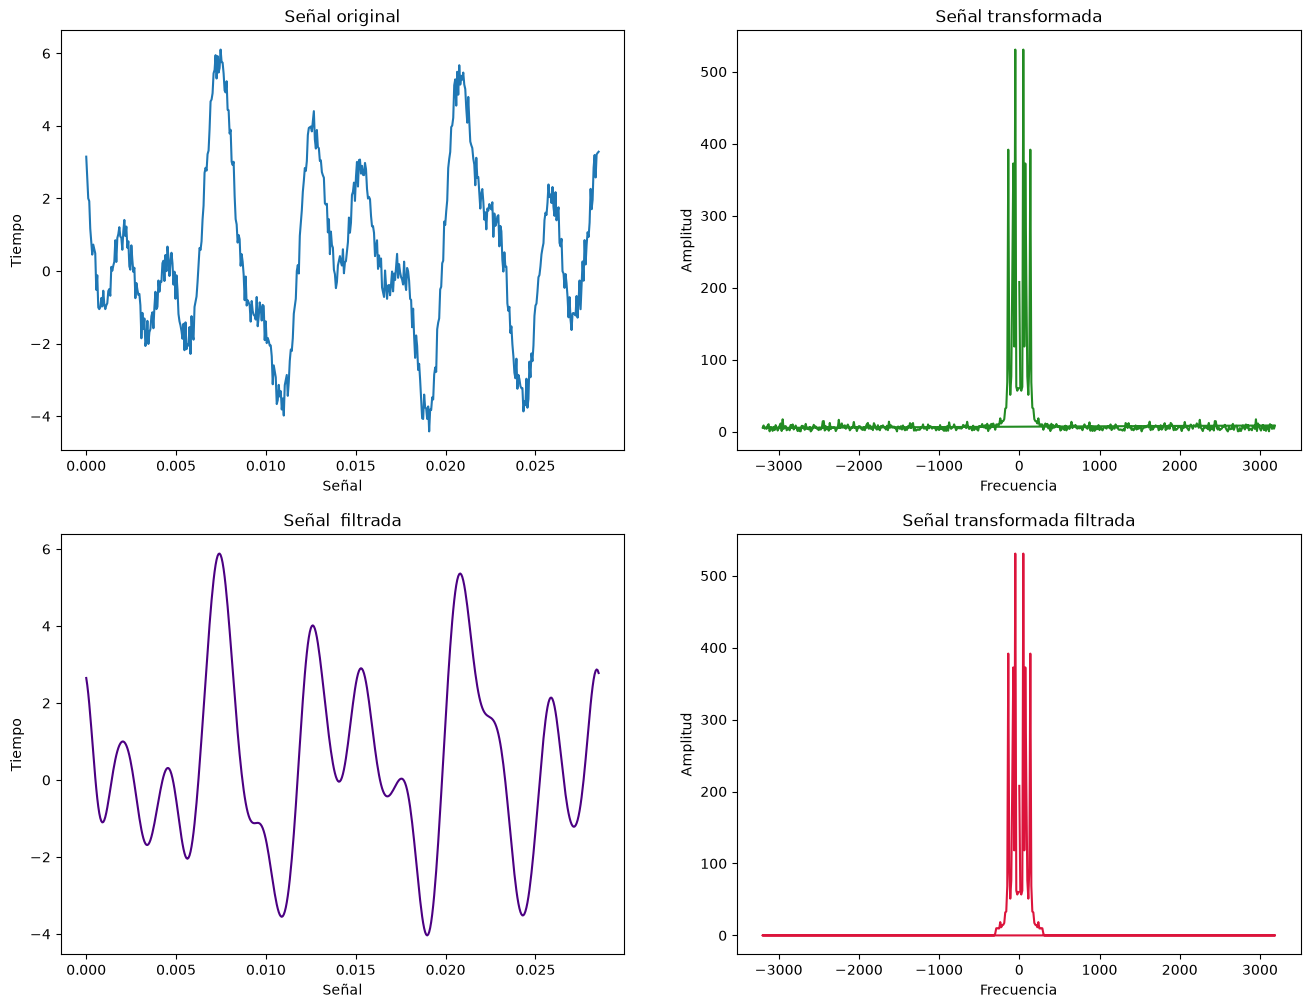

In [109]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq, ifft

# 1) Almacene los datos de signal.dat. La columna 1 es el tiempo y la columna 2 es su señal f(t).
#Grafique su señal en función del tiempo.
ruta = "signal.dat"
archivo = np.genfromtxt(ruta, delimiter=",")
tiempo = archivo[:,0]
señal = archivo[:,1]
tamaño = len(tiempo)
dt1 = 1 / (6400)

fig2, ((ax1,ax2),(ax3,ax4)) = plt.subplots(2,2, figsize=(16,12))

ax1.plot(tiempo, señal)
ax1.set_ylabel("Tiempo")
ax1.set_xlabel("Señal")
ax1.set_title("Señal original")

# 2) Use fftfreq (BONO si usa su implementación propia) y haga una gráfica de su transformada de fourier en función de las frecuencias.
frecuencia = Frecuencias_propia(dt1, tamaño)
transformada = Fourier_propia(señal, tamaño)

ax2.plot(frecuencia, np.abs(transformada), color = "forestgreen")
ax2.set_ylabel("Amplitud")
ax2.set_xlabel("Frecuencia")
ax2.set_title("Señal transformada")


# 3) Haga un filtro pasa bajos que le permita filtrar el ruido de la señal del punto 1. #
#Use la gráfica de la transformada de fourier del punto 3 para determinar un valor apropiado de la frecuencia de corte que debe usar para filtrar dicho ruido de alta frecuencia.
for l in range(tamaño):
  if np.abs(frecuencia[l]) > 300:
    transformada[l] = 0

ax4.plot(frecuencia, np.abs(transformada), color = "crimson")
ax4.set_ylabel("Amplitud")
ax4.set_xlabel("Frecuencia")
ax4.set_title("Señal transformada filtrada")

# 4) Grafique la señal filtrada
señal_filtrada = np.real(ifft(transformada,tamaño))

ax3.plot(tiempo, señal_filtrada, color = "indigo")
ax3.set_ylabel("Tiempo")
ax3.set_xlabel("Señal")
ax3.set_title("Señal  filtrada")

plt.show()

EJERCICIO 3 (hagánlo cuando terminen los de transformada de Fourier 2D): FILTROS VIOLIN-TROMPETA

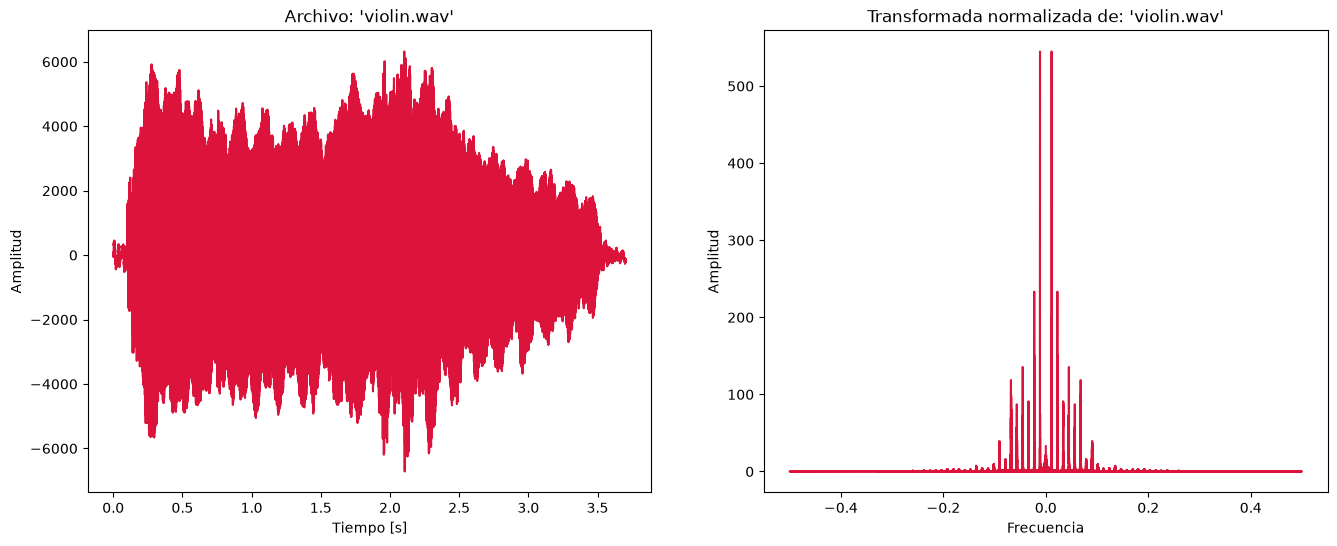

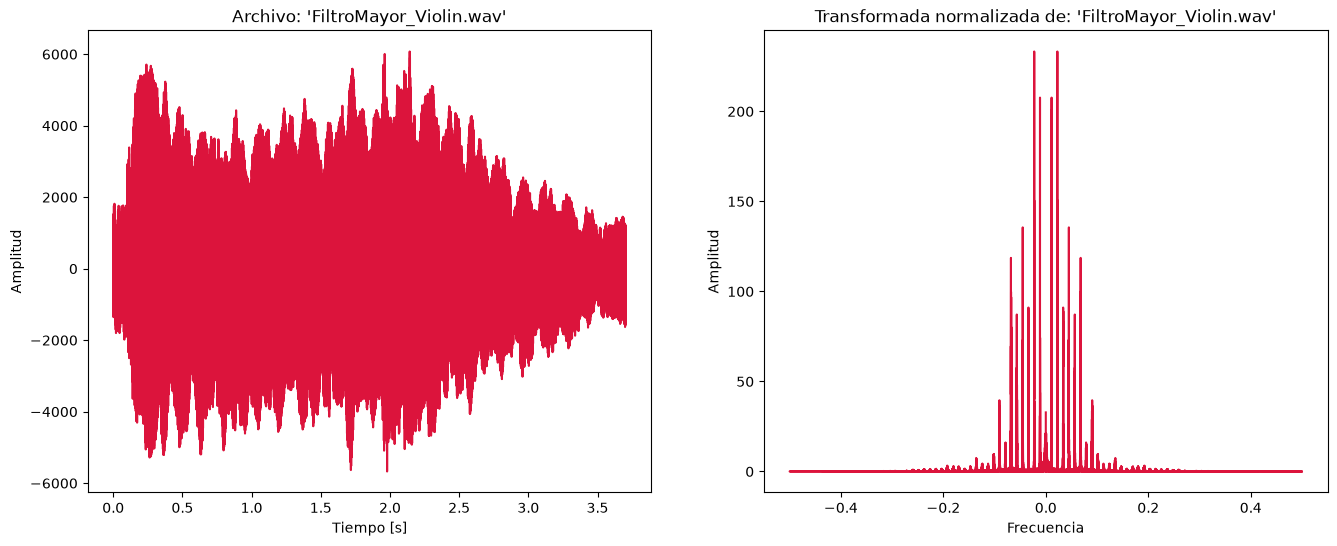

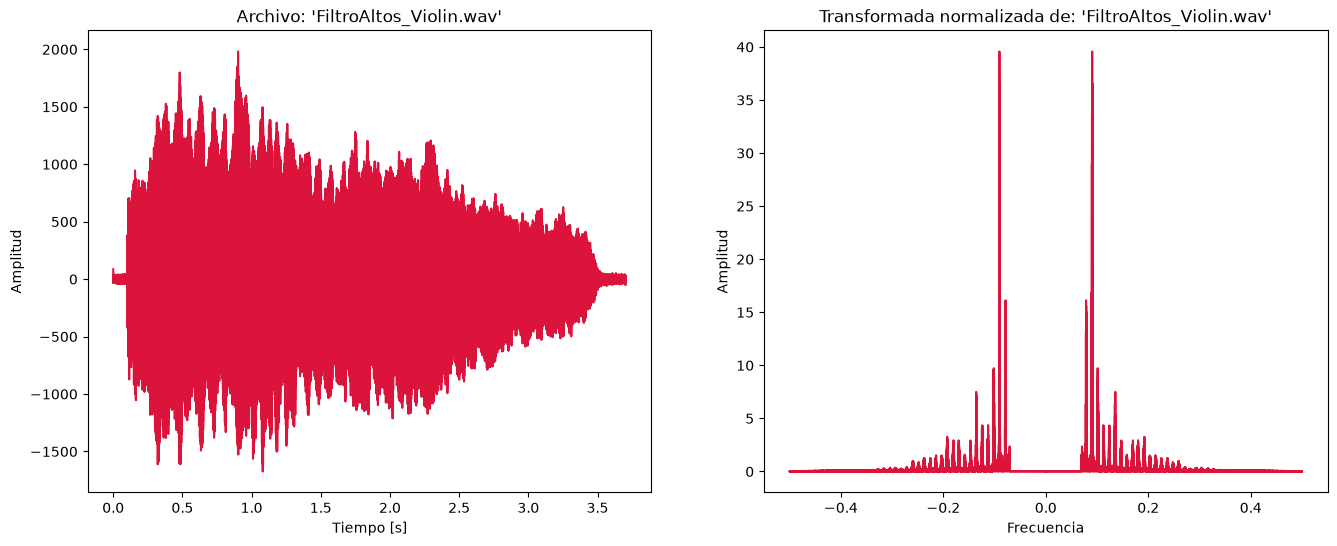

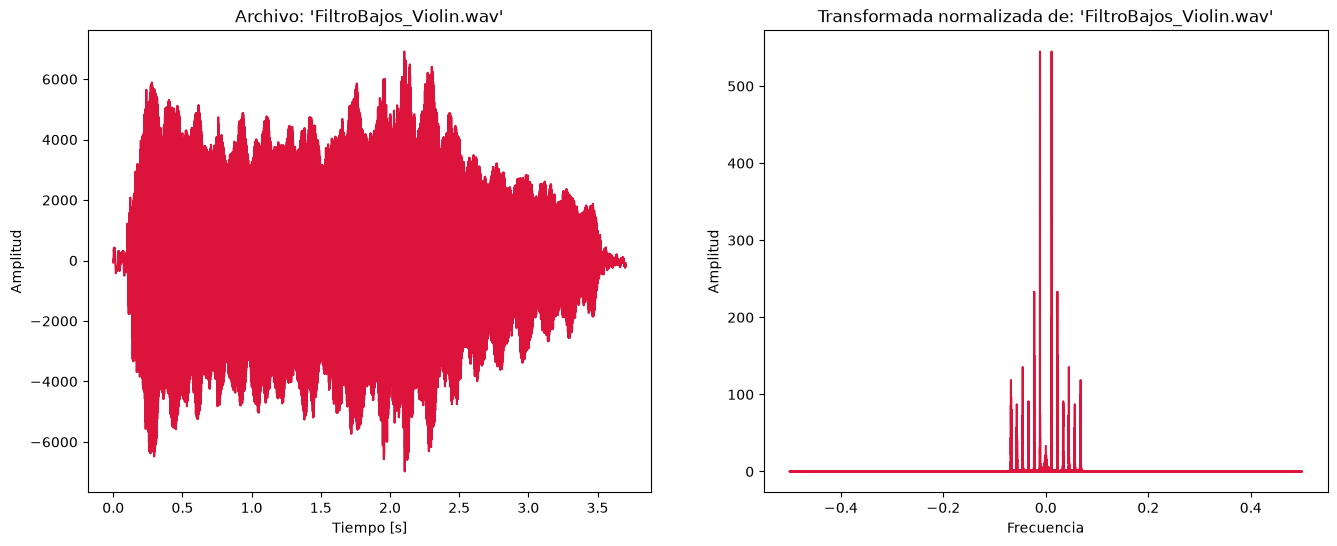

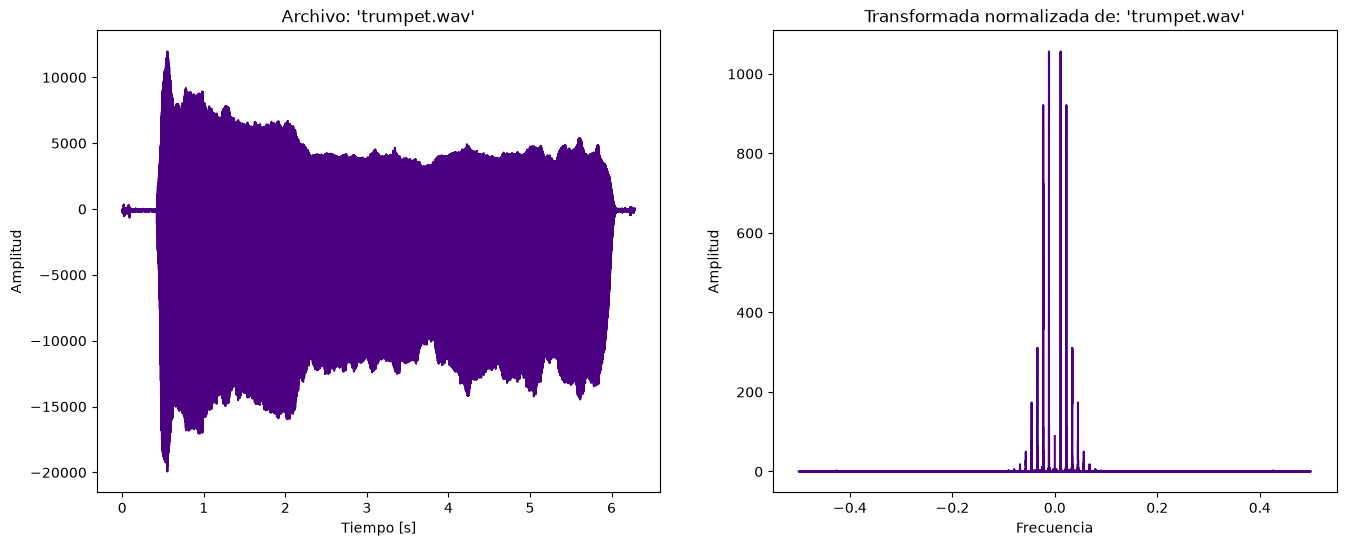

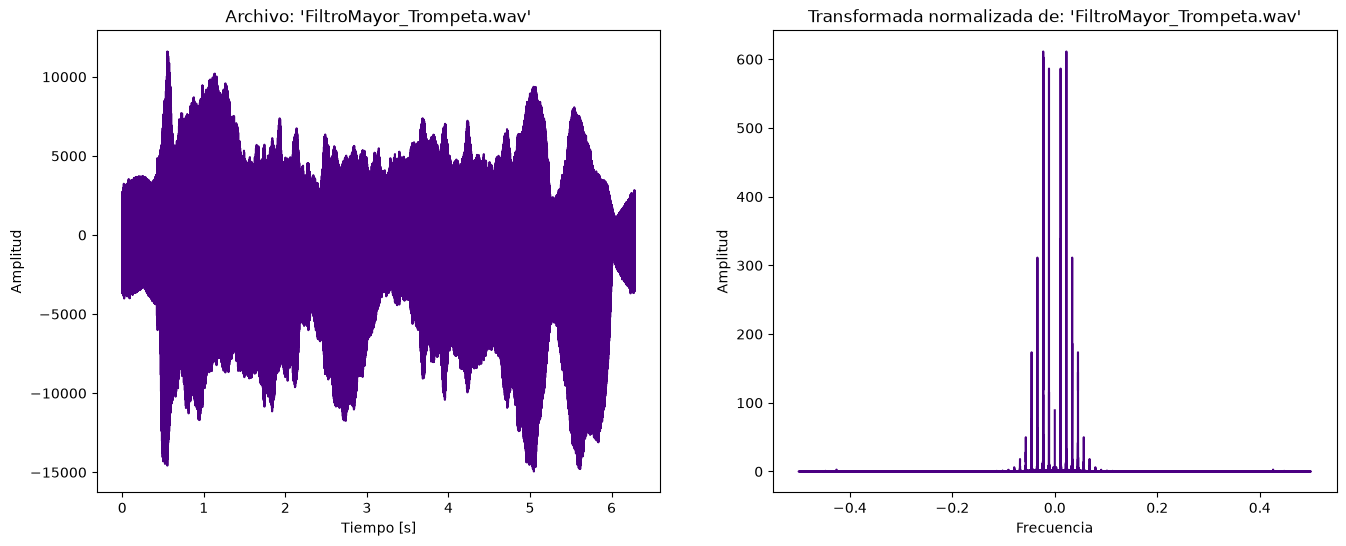

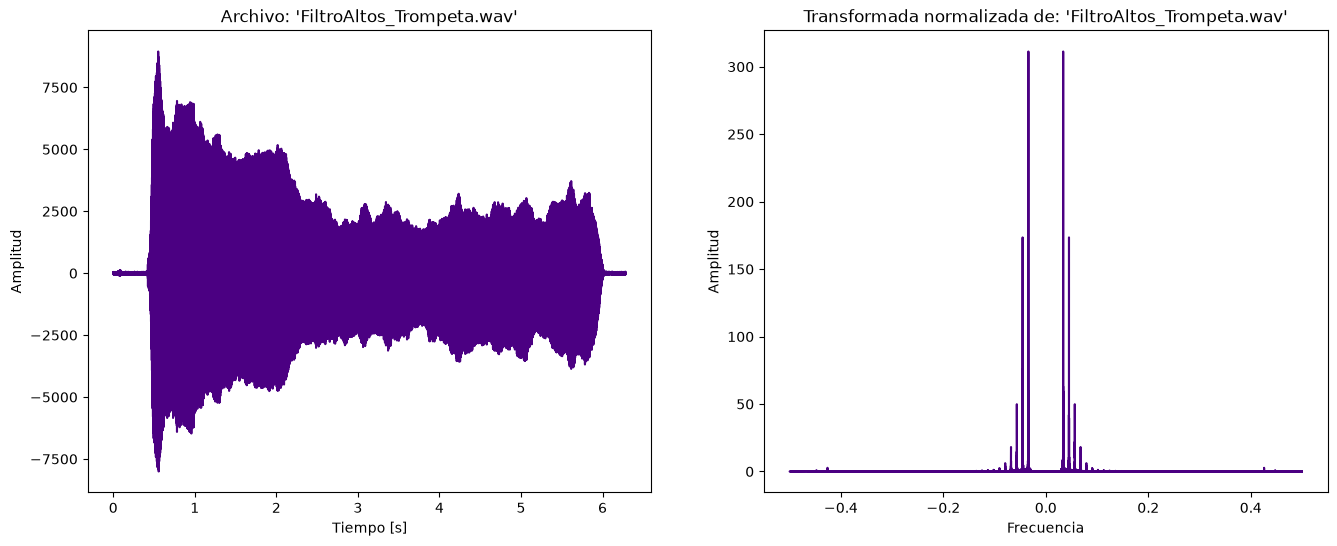

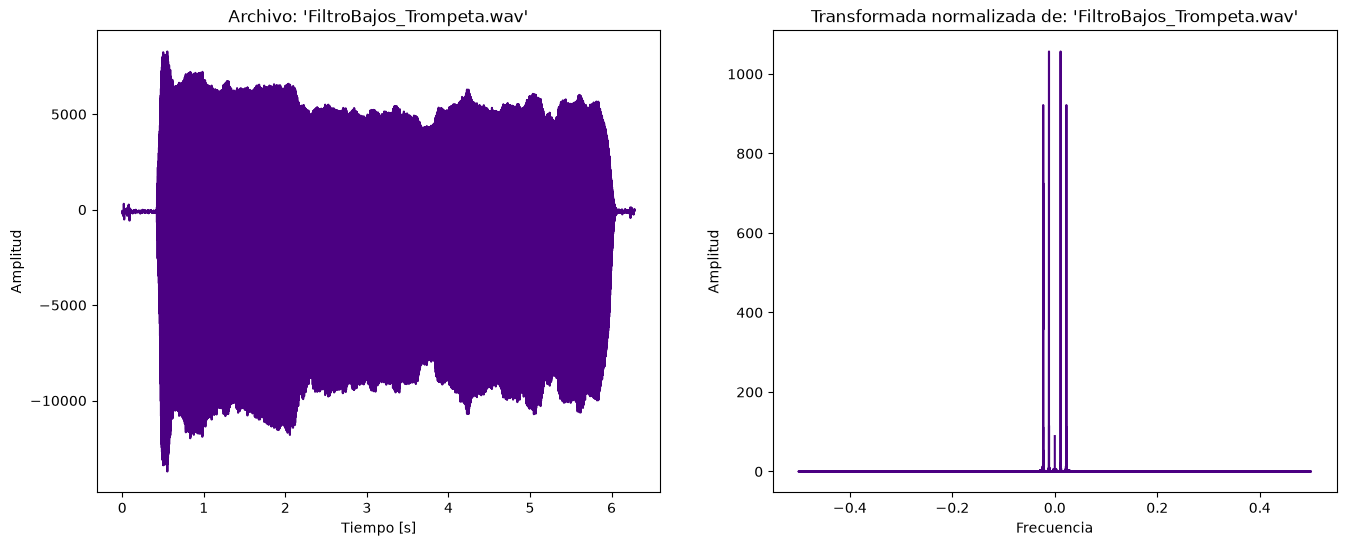

In [ ]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq
from scipy.io import wavfile

# 1) Almacene los datos de violin.wav (use wav.read('violin.wav')).
#Grafique su señal en función del tiempo y guarde dicha gráfica.

# La estructura la estoy obteniendo de la documentación: https://docs.scipy.org/doc/scipy/reference/generated/scipy.io.wavfile.read.html#scipy.io.wavfile.read
samplerate_V, violin = wavfile.read("violin.wav")
tamaño_V = violin.shape[0]
duracion_V = tamaño_V/samplerate_V
tiempo_V = np.linspace(0., duracion_V, tamaño_V)

fig3, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_V, violin, color="crimson")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'violin.wav'")

# 2) Use fftfreq (BONO si usa su implementación propia) y haga una gráfica de su transformada de fourier en función de las frecuencias.
frec_V = Frecuencias_propia(1, tamaño_V)
transf_V = fft(violin)

ax2.plot(frec_V, np.abs(transf_V)/tamaño_V, color="crimson")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'violin.wav'")
plt.show()

# 3) Haga un filtro que elimine el pico principal. Grafique su señal filtrada.
#Escuche (OJO con el volumen!) sus datos filtrados.
#Repita lo anterior haciendo un filtro pasaaltos y uno pasabajos.

# PICO PRINCIPAL:
V_maximo = np.max(np.abs(transf_V)) - (300*tamaño_V) # El factor de 300 es porque hay varios picos contiguos al máximo que siguen aportando de manera similar
transf_V_copia = np.copy(transf_V)
# La idea de usar np.where la obtuve de: https://stackoverflow.com/a/20297066/33033931
transf_V_copia[np.where(np.abs(transf_V_copia) > V_maximo)] = 0

Violin_Mayor = ifft(transf_V_copia)

fig30, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_V, np.real(Violin_Mayor), color="crimson")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'FiltroMayor_Violin.wav'")


ax2.plot(frec_V, np.abs(transf_V_copia)/tamaño_V, color="crimson")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'FiltroMayor_Violin.wav'")
plt.show()

t = np.linspace(0., 1., samplerate_V)
wavfile.write("FiltroMayor_Violin.wav", samplerate_V, np.real(Violin_Mayor).astype(np.int16))


# FILTRO PASAALTOS:
transf_V_altos = np.copy(transf_V)

transf_V_altos[np.where(np.abs(frec_V) < 0.07)] = 0

Violin_Altos = ifft(transf_V_altos)

fig31, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_V, np.real(Violin_Altos), color="crimson")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'FiltroAltos_Violin.wav'")

ax2.plot(frec_V, np.abs(transf_V_altos)/tamaño_V, color="crimson")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'FiltroAltos_Violin.wav'")
plt.show()

t = np.linspace(0., 1., samplerate_V)
wavfile.write("FiltroAltos_Violin.wav", samplerate_V, np.real(Violin_Altos).astype(np.int16))


# FILTRO PASABAJOS:
transf_V_bajos = np.copy(transf_V)

transf_V_bajos[np.where(np.abs(frec_V) > 0.07)] = 0

Violin_Bajos = ifft(transf_V_bajos)

fig31, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_V, np.real(Violin_Bajos), color="crimson")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'FiltroBajos_Violin.wav'")

ax2.plot(frec_V, np.abs(transf_V_bajos)/tamaño_V, color="crimson")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'FiltroBajos_Violin.wav'")
plt.show()

t = np.linspace(0., 1., samplerate_V)
wavfile.write("FiltroBajos_Violin.wav", samplerate_V, np.real(Violin_Bajos).astype(np.int16))


#NOTA: para el manejo de archivos .wav mire la documentacion de python de input-output en https://docs.scipy.org/doc/scipy-0.14.0/reference/io.html)

##############################################################################################
# 4) repita lo anterior para trumpet.wav que es la señal correspondiente al sonido de una trompeta tocando la misma nota que el violín del puntos anterior.

samplerate_T, trompeta = wavfile.read("trumpet.wav")
trompeta = trompeta[:-1]
tamaño_T = trompeta.shape[0]
duracion_T = tamaño_T/samplerate_T
tiempo_T = np.linspace(0., duracion_T, tamaño_T)
frec_T = Frecuencias_propia(1, tamaño_T)
transf_T = fft(trompeta)

fig3, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_T, trompeta, color="indigo")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'trumpet.wav'")

ax2.plot(frec_T, np.abs(transf_T)/tamaño_T, color="indigo")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'trumpet.wav'")
plt.show()

# PICO PRINCIPAL:
T_maximo = np.max(np.abs(transf_T)) - (400*tamaño_T) # A diferencia del violin fue necesario un factor de 400 para notar cambios
transf_T_copia = np.copy(transf_T)
transf_T_copia[np.where(np.abs(transf_T_copia) >= T_maximo)] = 0

Trompeta_Mayor = ifft(transf_T_copia)

fig30, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_T, np.real(Trompeta_Mayor), color="indigo")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'FiltroMayor_Trompeta.wav'")


ax2.plot(frec_T, np.abs(transf_T_copia)/tamaño_T, color="indigo")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'FiltroMayor_Trompeta.wav'")
plt.show()

t = np.linspace(0., 1., samplerate_T)
wavfile.write("FiltroMayor_Trompeta.wav", samplerate_T, np.real(Trompeta_Mayor).astype(np.int16))


# FILTRO PASAALTOS:
transf_T_altos = np.copy(transf_T)

transf_T_altos[np.where(np.abs(frec_T) < 0.03)] = 0

Trompeta_Altos = ifft(transf_T_altos)

fig31, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_T, np.real(Trompeta_Altos), color="indigo")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'FiltroAltos_Trompeta.wav'")

ax2.plot(frec_T, np.abs(transf_T_altos)/tamaño_T, color="indigo")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'FiltroAltos_Trompeta.wav'")
plt.show()

t = np.linspace(0., 1., samplerate_T)
wavfile.write("FiltroAltos_Trompeta.wav", samplerate_T, np.real(Trompeta_Altos).astype(np.int16))


# FILTRO PASABAJOS:
transf_T_bajos = np.copy(transf_T)

transf_T_bajos[np.where(np.abs(frec_T) > 0.03)] = 0

Trompeta_Bajos = ifft(transf_T_bajos)

fig31, (ax1, ax2) = plt.subplots(1,2, figsize=(16,6))
ax1.plot(tiempo_T, np.real(Trompeta_Bajos), color="indigo")
ax1.set_xlabel("Tiempo [s]")
ax1.set_ylabel("Amplitud")
ax1.set_title("Archivo: 'FiltroBajos_Trompeta.wav'")

ax2.plot(frec_T, np.abs(transf_T_bajos)/tamaño_T, color="indigo")
ax2.set_xlabel("Frecuencia")
ax2.set_ylabel("Amplitud")
ax2.set_title("Transformada normalizada de: 'FiltroBajos_Trompeta.wav'")
plt.show()

t = np.linspace(0., 1., samplerate_T)
wavfile.write("FiltroBajos_Trompeta.wav", samplerate_T, np.real(Trompeta_Bajos).astype(np.int16))

EJERCICIO 4: FILTRO RUIDO PERIÓDICO IMAGEN 2D

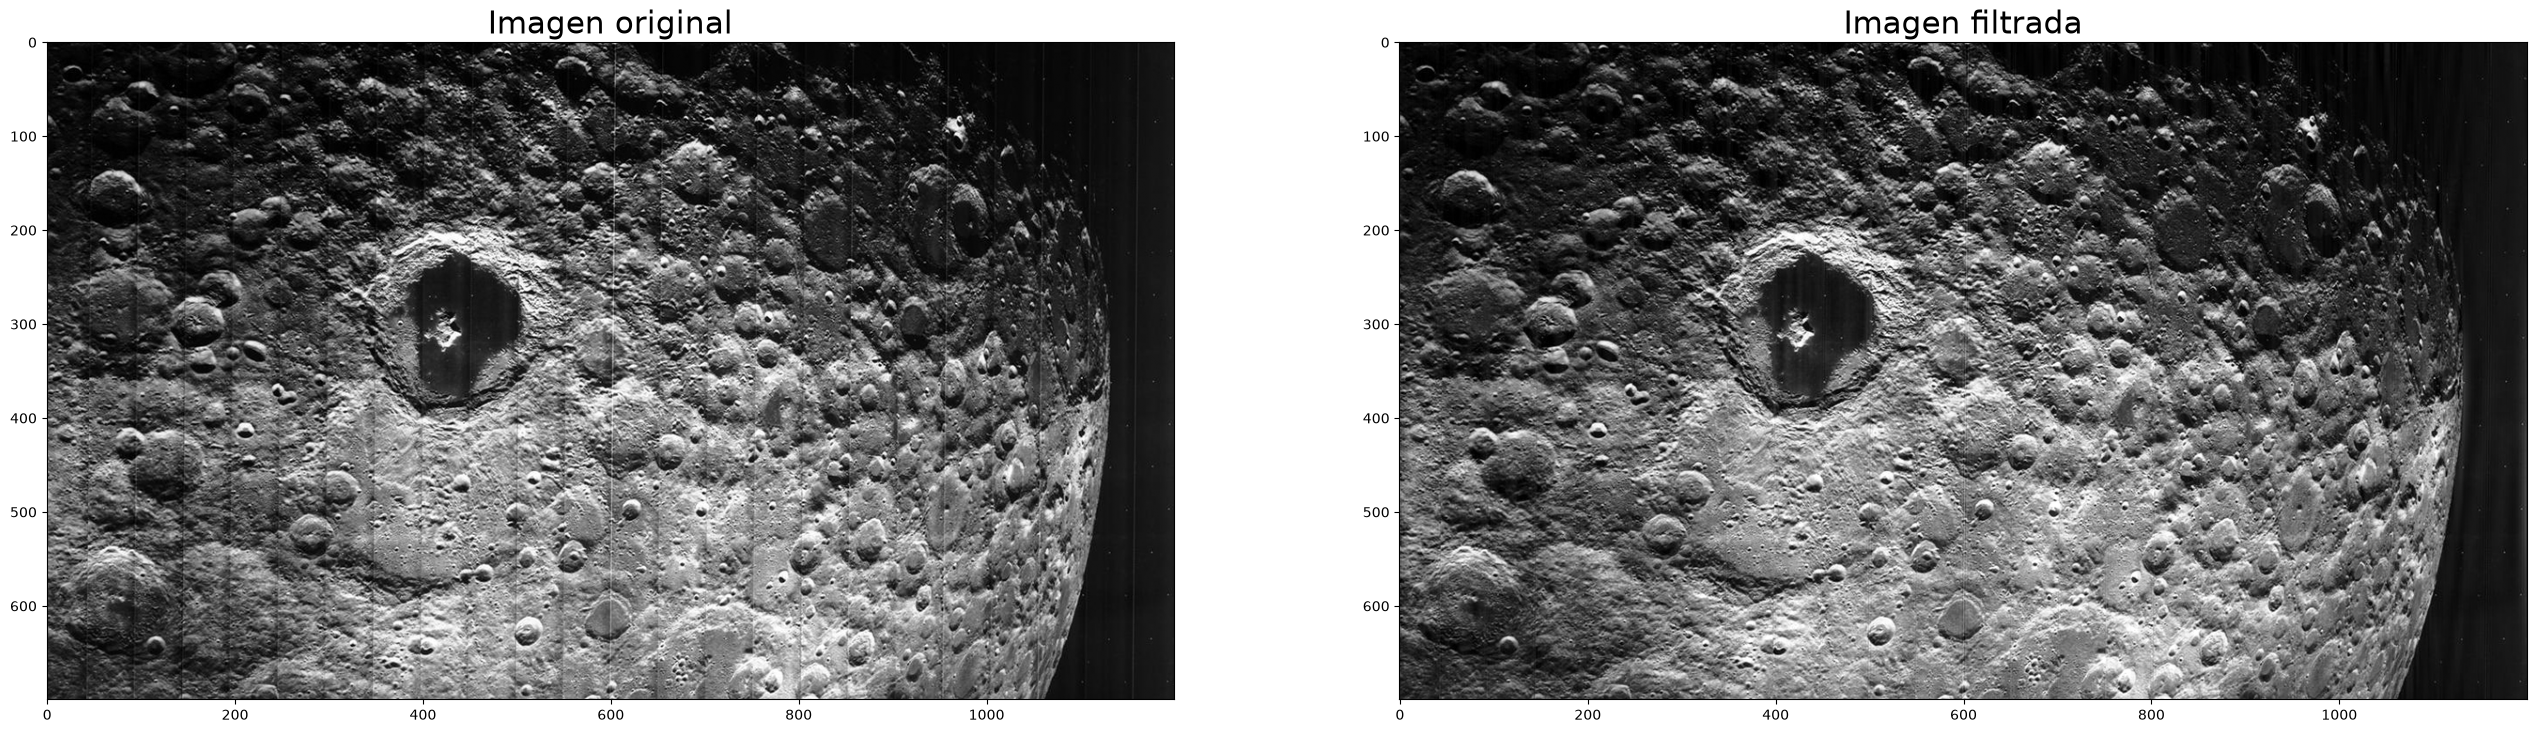

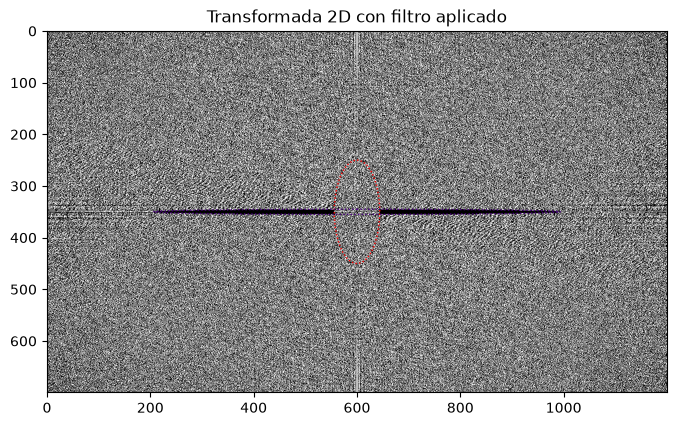

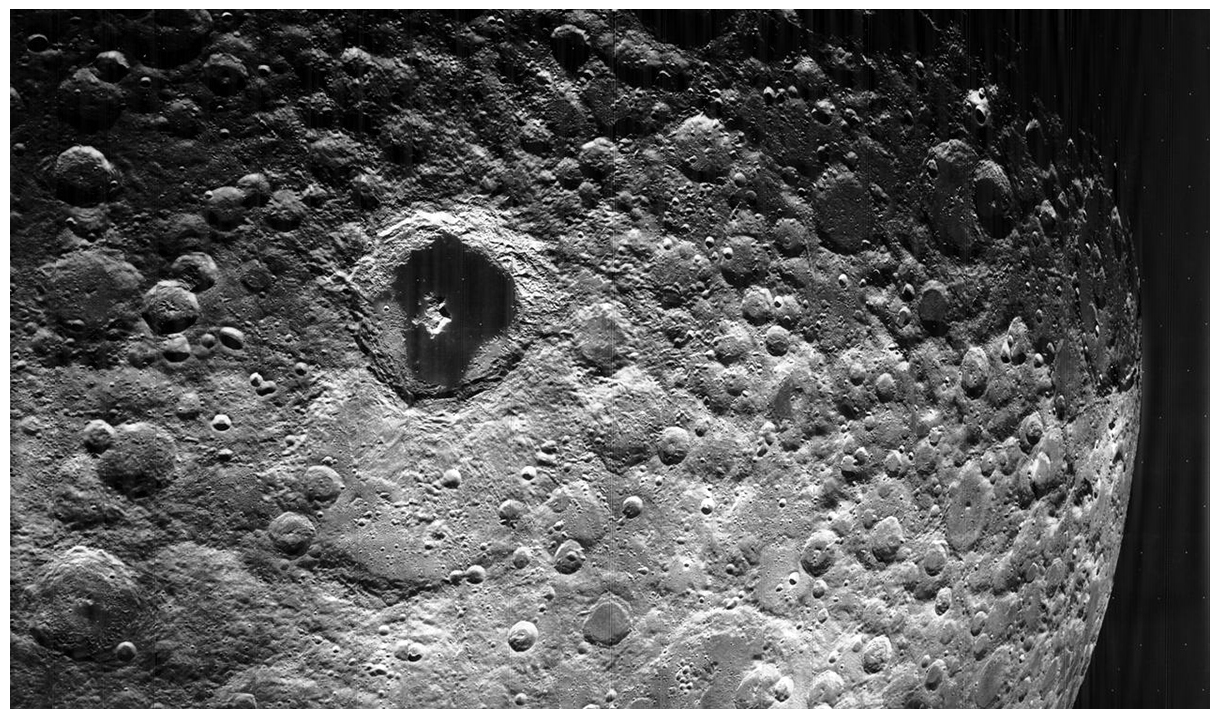

In [55]:
import numpy as np
import matplotlib.pylab as plt
from scipy.fftpack import fft, fftfreq, fft2, ifft2, fftshift, ifftshift
from matplotlib.patches import Ellipse

# 1) Almacene los datos de la imagen (use imread: https:/req/matplotlib.org/stable/apireq/_as_gen/matplotlib.pyplot.imread.html)
dir_im = "moon.jpg"

img_data = plt.imread(dir_im)

# 2) Use la librería de scipy de transformada de fourier en 2d y la trasnformada inversa
#(https://docs.scipy.org/dreqoc/scipy/reference/generated/scipy.fft.fft2.html)
#para hacer un código que filtre el ruido periodico que tiene la imagen de la luna.
transf_2D = fft2(img_data)
transf_Shift = fftshift(transf_2D)
Ancho = len(img_data[0,:])
Alto =  len(img_data[:,0])

# Parámetros para ajustar los semiejes de dos elipses que actuarán sobre la transformada en forma de filtro
# Estos valores se encontraron por prueba y error hasta un resultado bastante aceptable
semi_int1 = 100
semi_int2 = 44
semi_ext1 = 5
semi_ext2 = semi_int2 + 350

elipse_int = Ellipse(xy=(600, 350), width= 2*semi_int2, height=2*semi_int1, edgecolor="red", fc="none" , lw=1, ls=":")
elipse_ext = Ellipse(xy=(600, 350), width= 2*semi_ext2, height=2*semi_ext1, edgecolor="indigo", fc="none" , lw=1, ls=":")

for w in range(Ancho):
    for h in range(Alto):
        # Creo dos elipses, una interna y otra externa, lo que se encuentre dentro de la exterior
        # y no se encuentre dentro de la interior se hará cero
        Elipse_int = (((h-Alto/2)/semi_int1)**2 + ((w-Ancho/2)/semi_int2)**2) 
        Elipse_ext = (((h-Alto/2)/semi_ext1)**2 + ((w-Ancho/2)/semi_ext2)**2)

        if (Elipse_int > 1) and (Elipse_ext < 1): # Rectifico la Elipse
            transf_Shift[h,w] = 0
            
fig4, (ax1,ax2) = plt.subplots(1,2, figsize=(32,12))

ax1.imshow(img_data, cmap='gray', vmin=0, vmax=255)
ax1.set_title("Imagen original", fontsize = 22)

#3) haga una gráfica de la imagen filtrada y guárdela en LunaFiltrada.png
img_filtrada = np.abs(ifft2(ifftshift(transf_Shift)))
ax2.imshow(img_filtrada, cmap='gray', vmin=0, vmax=255)
ax2.set_title("Imagen filtrada", fontsize = 22)
plt.show()

# Gráfica de la transformada 2D
fig40, ax = plt.subplots(figsize=(8,6))
plt.imshow(np.real(transf_Shift), cmap='gray', vmin=0, vmax=255)
ax.add_patch(elipse_int)
ax.add_patch(elipse_ext)
plt.title("Transformada 2D con filtro aplicado", fontsize = 12)
plt.show()

#imagen: https://blogs.3ds.com/simulia/wp-content/uploads/sites/18/2019/07/NASA_Moon.jpg
#guardado de la figura:

# Las siguientes 4 líneas de códio las obtuve de: 
# https://en.moonbooks.org/Articles/How-to-create-a-figure-with-no-axes-or-labels-using-matplotlib-/
# Con el fin de guardar la imagen "LunaFiltrada.png" sin los ejes.
fig41 = plt.figure(figsize=(12,7))
ax = plt.Axes(fig41, [0., 0., 1., 1.])
ax.set_axis_off()
fig41.add_axes(ax)

plt.imshow(img_filtrada, cmap='gray', vmin=0, vmax=255)
plt.savefig("LunaFiltrada.png")

EJERCICIO 5: FASE Y MAGNITUD

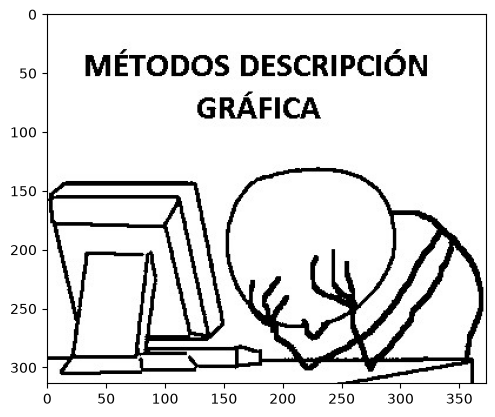

In [82]:
#Recupere la imagen original a partir de la fase y la amplitud de la transformada de fourier (archivos amplitude.dat y phase.dat).
#Recuerde que la transformada de fourier tiene una parte real y una imaginaria
#y recuerde tambien que un numero complejo se puede escribir a partir de la fase y la magnitud que son los datos que usted tiene
#(http://webpages.ursinus.edu/lriley/ref/complex/node1.html)

#1)Descargue los datos de fase y magnitud
fase_data = "phase.dat"
amplitud_data = "magnitude.dat"

fase = np.genfromtxt(fase_data, delimiter=" ")          # θ
amplitud = np.genfromtxt(amplitud_data, delimiter=" ")  # r

#2) construya la transformada de fourier
datos_5 = np.abs(amplitud) * np.exp((0+1j) * fase)  # z = |r|e^{iθ}

#3) Obtenga la imagen haciendo la transformada inversa
imagen_5 = ifft2(datos_5)
plt.imshow(np.real(imagen_5), cmap='gray', vmin=0, vmax=255)
plt.show()

# JAJAJA, profe, no me esperaba esa imágen como resultado xd